- By: Oliver Tschudi Madsen
- Github : https://github.com/OTMadsen/IND320
- Streamlit App : ind320-4eqw3p5dwcvvqtwfndtuwa.streamlit.app
- Screencast (YouTube) : https://youtu.be/QC1LSYNntEk

This was a bit more theoretical assignment with more math applied, so I consulted to some AI to help out with the heavier functions, such as the DCT and the LOF. They have been thorougly tested, and displays promising results, with good and descriptive plots. 

I have now also done an extensive makeover with the app layout. Instead of having updating the apps with new changes, I have broken them down into smaller and more readable applications. This improved the structure in th GitHub repository. This was also done using a bit of help from AI to save some time. 


In [1]:
#The data was saved locally as geo.json data which needed a new separate library to be read. 
%pip install geopandas shapely

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Columns:
<bound method IndexOpsMixin.tolist of Index(['objectid', 'budomr', 'globalid', 'st_area(shape)',
       'st_perimeter(shape)', 'geometry'],
      dtype='object')>
   objectid budomr globalid  st_area(shape)  st_perimeter(shape)  \
0         1   NO 1     None    6.052902e+10         1.657761e+06   
1         2   NO 2     None    6.875969e+10         1.256473e+06   
2         3   NO 3     None    1.042199e+11         1.773323e+06   
3         4   NO 4     None    2.032500e+11         3.385499e+06   
4         5   NO 5     None    3.334870e+10         1.106762e+06   

                                            geometry  
0  POLYGON ((11.80905 62.8288, 11.80786 62.82916,...  
1  POLYGON ((5.74061 60.3517, 5.73955 60.35362, 5...  
2  POLYGON ((10.87378 65.41986, 10.57806 65.47018...  
3  POLYGON ((28.33596 71.29423, 28.31789 71.29557...  
4  POLYGON ((7.41477 61.85483, 7.4125 61.85751, 7...  
5


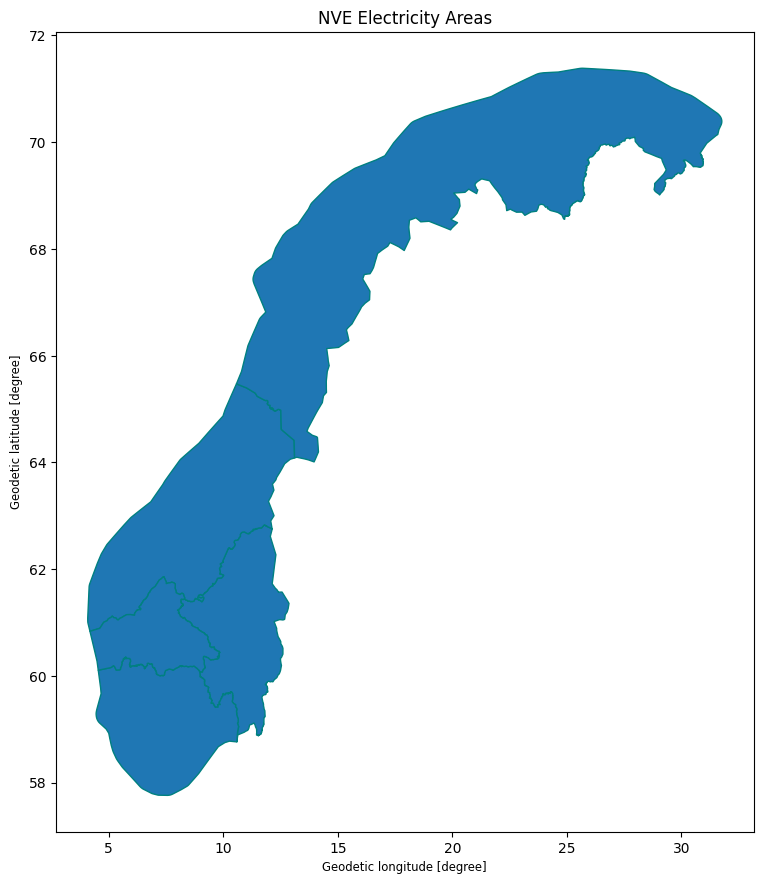

In [4]:
#Import the necessary libraries for the task, now with geopandas as a new addition. This will help read the new data. 
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
import requests
from pathlib import Path
import matplotlib.dates as mdates 

#The corresponding data has been downloaded, so now we just load these

electricity_areas = gpd.read_file("electricity_areas.geojson") #Implement Geopandas to read the file 

#Just to see how everything looks:

print("Columns:")
print(electricity_areas.columns.tolist)

print(electricity_areas.head(10))

print(len(electricity_areas))

electricity_areas.plot(

    figsize=(9,12),
    edgecolor="teal"
)

plt.title("NVE Electricity Areas")
plt.show()

In [ ]:
#Using the data and our libraries, we now sample 1000 from each region. 

# Column containing NO1, NO2, NO3, NO4, NO5

region_column = "budomr" #This was the data that corresponded to the Magasinstatistikk

# Work in a projected coordinate system (metres)
areas_projected = electricity_areas.to_crs("EPSG:25833")

# Reproducible random sampling
rng = np.random.default_rng(42)

def sample_points_in_polygon(polygon, n=1000):
    minx, miny, maxx, maxy = polygon.bounds
    points = []

    while len(points) < n:
        x = rng.uniform(minx, maxx)
        y = rng.uniform(miny, maxy)

        point = Point(x, y)

        if polygon.covers(point):
            points.append(point)

    return points

# Generate points for every electricity region
sampled_data = []

for region, group in areas_projected.groupby(region_column):
    polygon = group.geometry.union_all()

    points = sample_points_in_polygon(polygon, n=1000)

    for point in points:
        sampled_data.append({
            "region": region,
            "geometry": point
        })

# Create a GeoDataFrame
sampled_locations = gpd.GeoDataFrame(
    sampled_data,
    geometry="geometry",
    crs=areas_projected.crs
)

# Here we just convert to longitudes and latitude for our data
sampled_locations = sampled_locations.to_crs("EPSG:4326")

sampled_locations["longitude"] = sampled_locations.geometry.x
sampled_locations["latitude"] = sampled_locations.geometry.y

print("Total sampled locations:", len(sampled_locations))
print(sampled_locations.groupby("region").size())


Total sampled locations: 5000
region
NO 1    1000
NO 2    1000
NO 3    1000
NO 4    1000
NO 5    1000
dtype: int64


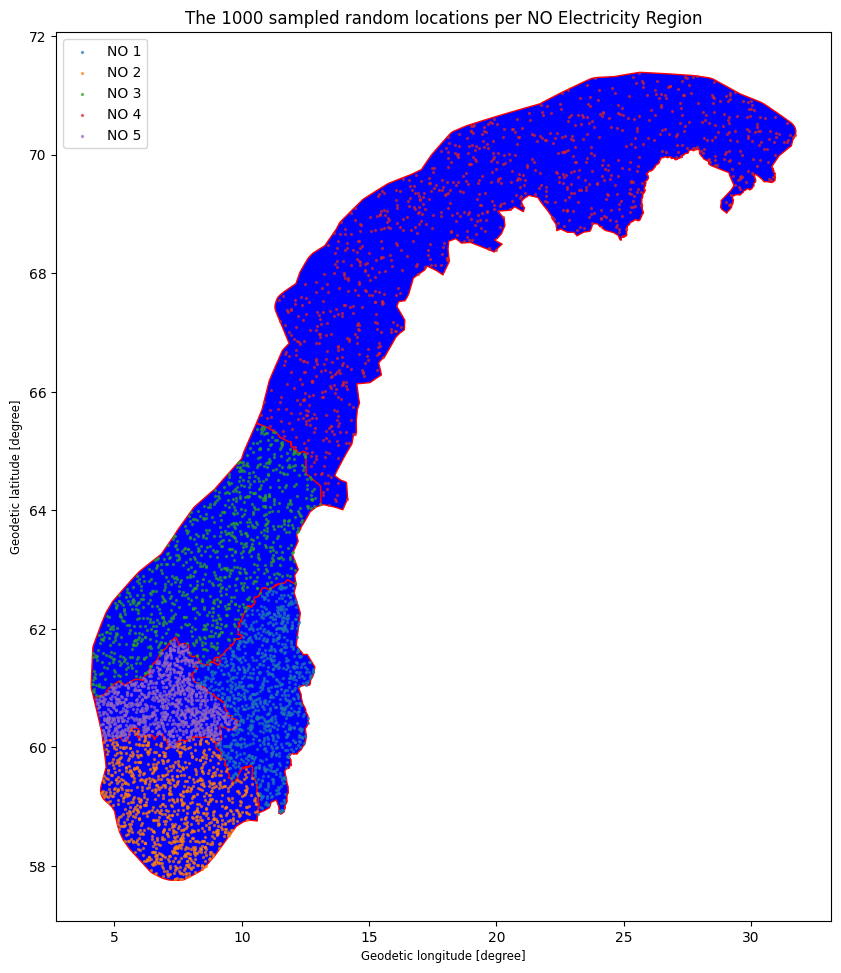

region
NO1    1000
NO2    1000
NO3    1000
NO4    1000
NO5    1000
dtype: int64


In [ ]:
#Now we just see if the sampled locations actually are located in their respective regions:

fig, ax = plt.subplots(figsize=(10, 12))

electricity_areas.plot(
    ax=ax,
    color="blue",
    edgecolor="red"
)


sampled_locations.plot(
    ax=ax,
    column="region",
    markersize=2,
    legend=True,
    alpha=0.6
)

ax.set_title("The 1000 sampled random locations per NO Electricity Region")
plt.show()

#These locations are necessary for later, so we just save them for later

sampled_locations[
    ["region", "longitude", "latitude"]
].to_csv("electricity_sampled_locations.csv", index=False)


#After som trial and error I found out the that there were spaces in the variables. The code did not allow to be read properly. 
sampled_locations["region"] = (
    sampled_locations["region"]
    .astype(str)
    .str.strip()
    .str.replace(" ", "", regex=False)
)

# Verify the corrected identifiers
print(sampled_locations.groupby("region").size())



In [ ]:
#Now we try again to sample the "NO3"-locations that were required for the assignment

no3_locations = sampled_locations[
    sampled_locations["region"] == "NO3"
]

print("NO3 locations found:", len(no3_locations))

print(no3_locations[
    ["region", "longitude", "latitude"]
])

#As from before we save the results for later

sampled_locations[
    ["region", "longitude", "latitude"]
].to_csv("electricity_sampled_locations.csv", index=False)

NO3 locations found: 1000
     region  longitude   latitude
2000    NO3   9.635666  63.572701
2001    NO3   9.955278  63.600475
2002    NO3   7.775188  62.576321
2003    NO3   7.746071  62.207005
2004    NO3   9.182132  63.831888
...     ...        ...        ...
2995    NO3  11.452548  63.188401
2996    NO3   4.624608  61.150321
2997    NO3   9.354524  62.381088
2998    NO3   7.786350  63.362742
2999    NO3   6.891934  62.105212

[1000 rows x 3 columns]


In [ ]:
# Now we define the download function for the sampled data with ERA5

def download_era5(region, start_date, end_date, location_index=0):

    locations = sampled_locations[
        sampled_locations["region"] == region
    ].reset_index(drop=True)

    if locations.empty:
        raise ValueError(f"No sampled locations found for {region}")

    if not 0 <= location_index < len(locations):
        raise IndexError("Invalid location index")

    latitude = float(locations.loc[location_index, "latitude"])
    longitude = float(locations.loc[location_index, "longitude"])

    url = "https://archive-api.open-meteo.com/v1/archive"

 
    params = {
        "latitude": latitude,
        "longitude": longitude,
        "start_date": start_date,
        "end_date": end_date,
        "hourly": ",".join([
            "temperature_2m",
            "precipitation",
            "rain",
            "snowfall",
            "relative_humidity_2m",
            "wind_speed_10m"
    ]),
    "models": "era5",
    "timezone": "UTC"
}
    
        


    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()

    data = response.json()

    if "hourly" not in data:
        raise ValueError(f"No hourly returned: {data}")

    #Here i convert the API response to a regular Pandas Dataframe
    weather_df = pd.DataFrame(data["hourly"])
    weather_df["time"] = pd.to_datetime(
        weather_df["time"],utc=True
    )

    weather_df["region"] = region
    weather_df["latitude"] = latitude
    weather_df["longitude"] = longitude

    return weather_df

In [ ]:
#Test out the function for the year 2024

weather_no3 = download_era5(
    region="NO3",
    start_date="2024-01-01",
    end_date="2024-12-31"
)

print(weather_no3.head())
print("Amount of observations made", len(weather_no3))

weather_no3.to_csv("NO3_ERA5_for_2024.csv", index=False)

                       time  temperature_2m  precipitation  rain  snowfall  \
0 2024-01-01 00:00:00+00:00            -3.7            0.0   0.0       0.0   
1 2024-01-01 01:00:00+00:00            -3.7            0.0   0.0       0.0   
2 2024-01-01 02:00:00+00:00            -3.6            0.0   0.0       0.0   
3 2024-01-01 03:00:00+00:00            -3.5            0.0   0.0       0.0   
4 2024-01-01 04:00:00+00:00            -3.3            0.0   0.0       0.0   

   relative_humidity_2m  wind_speed_10m region   latitude  longitude  
0                    66            36.0    NO3  63.572701   9.635666  
1                    66            36.4    NO3  63.572701   9.635666  
2                    65            37.2    NO3  63.572701   9.635666  
3                    65            37.8    NO3  63.572701   9.635666  
4                    65            37.6    NO3  63.572701   9.635666  
Amount of observations made 8784


  REGION
0     RV
1     RM
2     RN
3     RØ
4     RS

Coordinate system: EPSG:4326


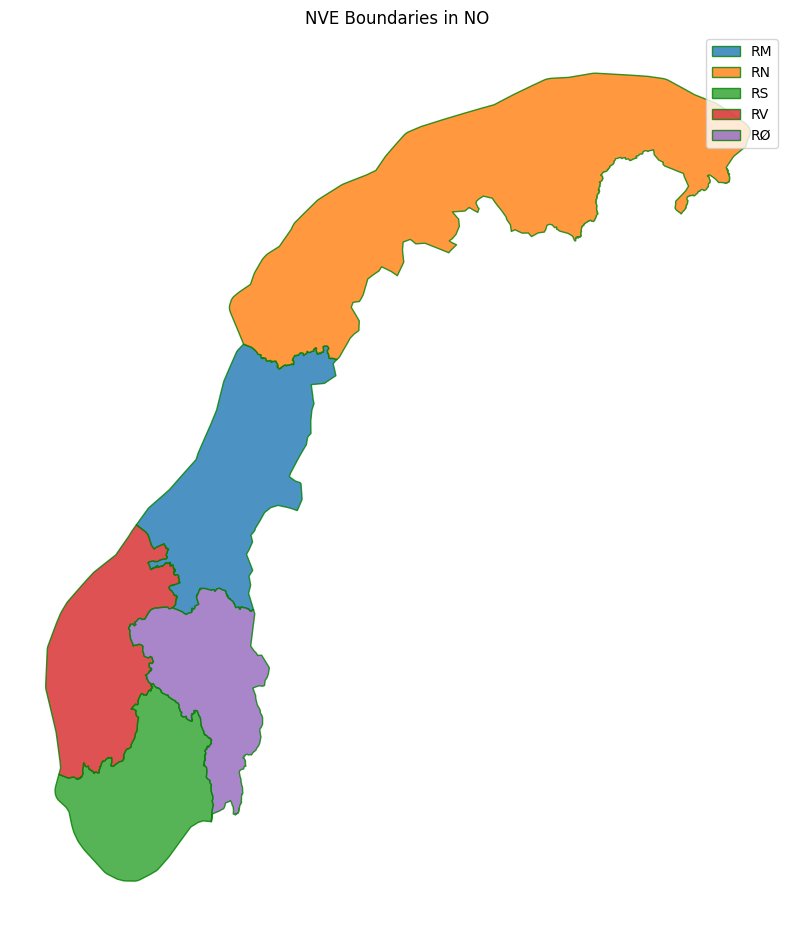

In [ ]:
#Now we continue on with the precipitation-area geographical data. These were to correspond with the magasinstatistikk-data for given regiions.

url = (

    "https://kart.nve.no/enterprise/rest/services/"
    "Mapservices/Administrasjon2/MapServer/0/query"
)

params = {
    "where": "1=1",
    "out": "REGION",
    "returnGeometry" : "true",
    "outSR": 4326,
    "f" : "GeoJSON"
}

response = requests.get(url, params=params, timeout=60)
response.raise_for_status()


data = response.json()

assert data.get("type") == "FeatureCollection"
assert len(data["features"]) > 0

Path("nve_regions.geojson").write_text(
    response.text,
    encoding="utf-8"
)

nve_regions = gpd.read_file("nve_regions.geojson")

print(nve_regions[["REGION"]])
print("\nCoordinate system:", nve_regions.crs)

#Further on, we plot the regions and examine given boundaries

fig, ax = plt.subplots(figsize=(10,12))

nve_regions.plot(
    ax=ax,
    column="REGION",
    legend=True,
    edgecolor="green",
    alpha=0.8
)

ax.set_title ("NVE Boundaries in NO")
ax.set_axis_off()

plt.show()

In [ ]:
#Now with the precipitation data in order, we sample a new 1000 for the new geographical zones (RS, RØ, RV, RM, RN) and not for the NO1-NO5
#We will use the existing dataframe

expected_regions = {"RS", "RØ", "RV", "RM", "RN"}


nve_regions["REGION"] = (
    nve_regions["REGION"].astype(str).str.strip().str.upper()
)

assert expected_regions == set(nve_regions["REGION"]), (
    f"Unexpected regions: {nve_regions["REGION"].unique()}"
)
#Converted to projected coordinate system

regions_projected = nve_regions.to_crs("EPSG:25833")

rng = np.random.default_rng(42)

def sample_points_in_region(polygon, n=1000):
    minx, miny, maxx, maxy = polygon.bounds
    points = []

    while len(points) < n:
        point = Point(
            rng.uniform(minx, maxx),
            rng.uniform(miny, maxy)
        )

        if polygon.covers(point):
            points.append(point)

    return points

sampled_data = []

for region, group in regions_projected.groupby("REGION"):
    polygon = group.geometry.union_all()

    points = sample_points_in_region(polygon, n=1000)

    for point in points:
        sampled_data.append({
            "region": region,
            "geometry": point,
        })

precipitation_locations = gpd.GeoDataFrame(
    sampled_data,
    geometry="geometry",
    crs=regions_projected.crs
).to_crs("EPSG:4326") 


precipitation_locations["longitude"] = precipitation_locations.geometry.x
precipitation_locations["latitude"] = precipitation_locations.geometry.y

#Group as said by assignment

region_groups = {
    "RS" : "East",
    "RØ" : "East",
    "RV" : "West",
    "RM" : "North",
    "RN" : "North"
}

precipitation_locations["area"] = (

    precipitation_locations["region"].map(region_groups)
)

print("Amount of loactions", len(precipitation_locations))
print("\nLocations per region:")
print(precipitation_locations.groupby("region").size())


Amount of loactions 5000

Locations per region:
region
RM    1000
RN    1000
RS    1000
RV    1000
RØ    1000
dtype: int64


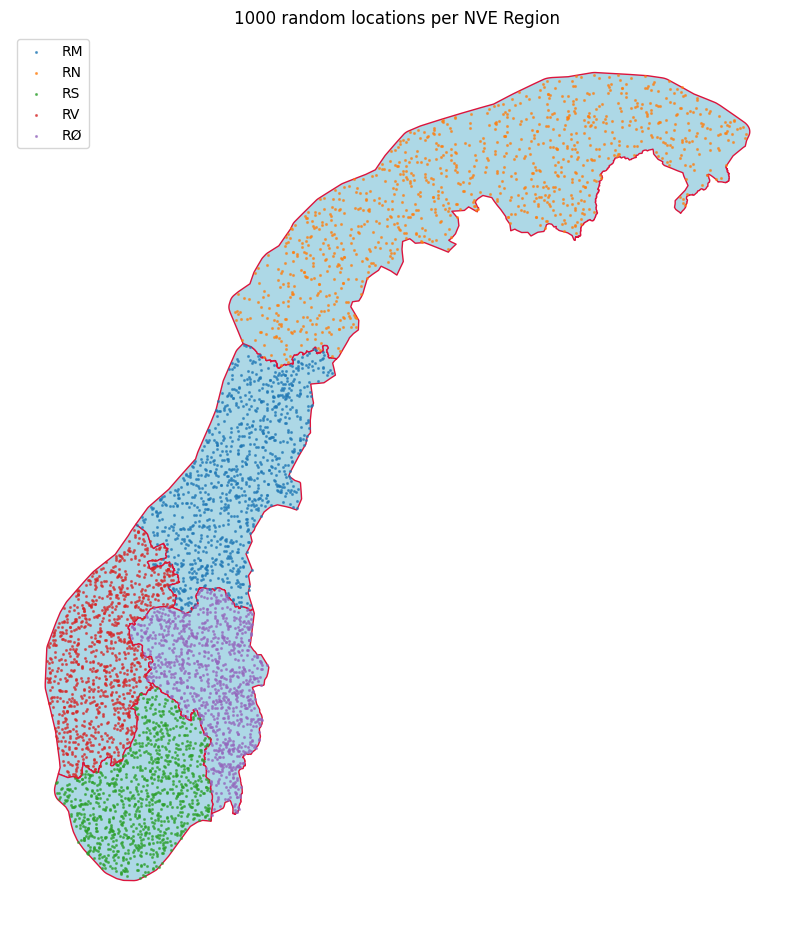

In [ ]:
#Now again to plot the locations over already existing regional boundaries

fig, ax = plt.subplots(figsize=(10,12))

nve_regions.plot(
    ax=ax,
    color="lightblue",
    edgecolor="crimson"
)

precipitation_locations.plot(
    ax=ax,
    column="region",
    markersize=1.5,
    legend=True,
    alpha=0.6
)


ax.set_title("1000 random locations per NVE Region")
ax.set_axis_off()

plt.show()


In [ ]:
#For the next part of the assignment we need more libraries for time-series analytic part of the assignment

from scipy.fft import dct, idct
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import RobustScaler
from statsmodels.tsa.seasonal import STL
from scipy.signal import spectrogram


#Our data from before is based on hours, so we simply aggregate these to daily values

weather_daily = weather_no3.copy()

weather_daily["time"] = pd.to_datetime(
    weather_daily["time"], utc=True
    )

weather_daily = (

    weather_daily
    .set_index("time")
    .resample("D")
    .agg({
        "precipitation":"sum",
        "temperature_2m": "mean"
    })
)

weather_daily = weather_daily.rename(columns={
    "precipitation": "precipitation_mm",
    "temperature_2m": "temperature_c"
})

print(weather_daily.head())
print("\nNumber of days:", len(weather_daily))
print("\nMissing values")
print(weather_daily.isna().sum())



                           precipitation_mm  temperature_c
time                                                      
2024-01-01 00:00:00+00:00               0.0      -3.566667
2024-01-02 00:00:00+00:00               0.0      -6.170833
2024-01-03 00:00:00+00:00               0.0      -7.929167
2024-01-04 00:00:00+00:00               0.8     -10.008333
2024-01-05 00:00:00+00:00               1.1      -7.595833

Number of days: 366

Missing values
precipitation_mm    0
temperature_c       0
dtype: int64


In [ ]:
#Apply the DCT. This will detect anomalies using its high-pass filtering and robust SPC bounadries. 
#The coding here as a bit heavy, so here I have consulted help from AI to help me develop the function properly.

def plot_precipitation_spc(
        weather,
        cutoff_cycles_per_year=6,
        n_std=3
):

    series = weather["precipitation_mm"].dropna().sort_index()

    if len(series) < 30:
        raise ValueError("At least 30 daily observations must be documented")

    if cutoff_cycles_per_year <= 0 or n_std <=0:
        raise ValueError("Cutoff and n_std must be positive.")

    values = series.to_numpy(dtype=float)

    n = len(values)

    coefficients = dct(values, norm="ortho")

    frequencies = np.arange(n) / (2*n)


    cutoff = cutoff_cycles_per_year / 365.25 # for an entire year

    low_frequency = coefficients.copy()
    low_frequency[frequencies >= cutoff] = 0

    baseline = idct(low_frequency, norm="ortho")


    residual = values - baseline

    #This robust should be able to estimate over the entire period
    median = np.median(residual)
    mad = np.median(np.abs(residual - median))

    robust_sigma = 1.4826 * mad

    if robust_sigma == 0:
        raise ValueError(
            "MAD is zero; robust control limits cannot be estimated properly."
        )

    lower = baseline + median - n_std * robust_sigma
    upper = baseline + median + n_std * robust_sigma

    outlier_mask = (values < lower) | (values > upper)

    fig, ax = plt.subplots(figsize=(13,5))

    ax.plot(
        series.index,
        values,
        label="Daily precipitation",
        color="darkblue",
        linewidth=1.2
    )

    ax.plot(
        series.index,
        upper,
        "--",
        color="orange",
        label="Upper SPC limit"
    )

    ax.plot(
        series.index,
        lower,
        "--",
        color="purple",
        label="Lower SPC Limit"
    )

    ax.scatter(
        series.index[outlier_mask],
        values[outlier_mask],
        color="violet",
        s=28,
        zorder=5,
        label="Outliers"
    )

    ax.set_title("NO3 Precipitation - DCT and Robust SPC")
    ax.set_xlabel("Date")
    ax.set_ylabel("Daily precipitation (mm)")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    outlier_df = pd.DataFrame({
        "precipitation_mm": values[outlier_mask],
        "lower_limit" : lower[outlier_mask],
        "upper_limit": upper[outlier_mask],
        "direction": np.where(
            values[outlier_mask] > upper[outlier_mask],
            "High",
            "Low"
        )
    }, index=series.index[outlier_mask])

    summary = {
        "total_observations":n,
        "outlier_count":int(outlier_mask.sum()),
        "outlier_percentage":100 * outlier_mask.mean(),
        "robust_sigma" : robust_sigma,
        "outliers": outlier_df
    }

    return fig, summary

    

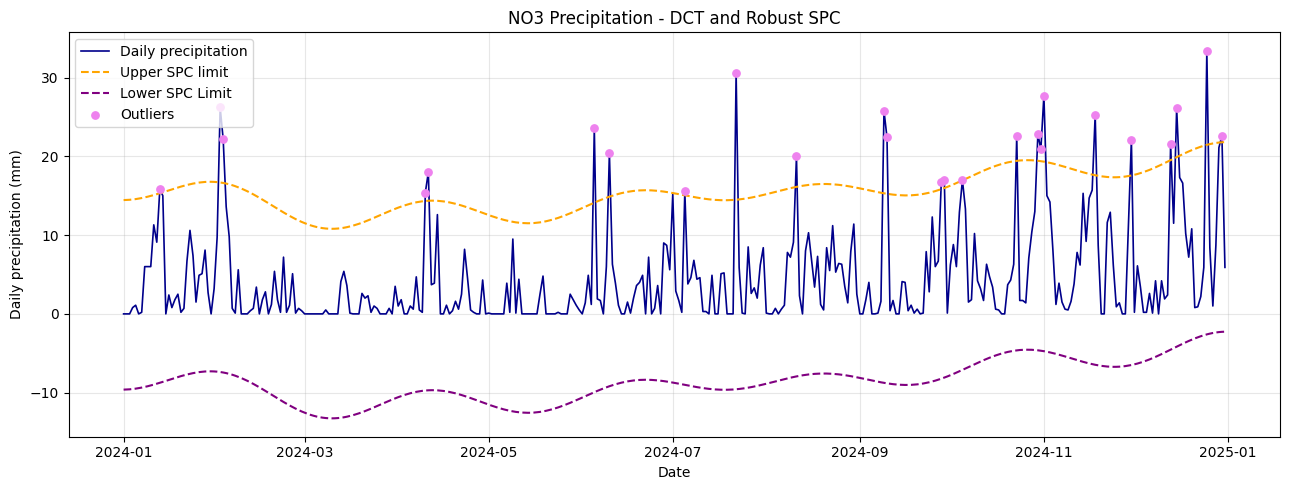

Observations: 366
Outliers: 25
Percentage: 6.830601092896176


,precipitation_mm,lower_limit,upper_limit,direction
time,,,,
2024-01-13 00:00:00+00:00,15.8,-8.745762,15.308932,High
2024-02-02 00:00:00+00:00,26.2,-7.376258,16.678436,High
2024-02-03 00:00:00+00:00,22.2,-7.437870,16.616824,High
2024-04-10 00:00:00+00:00,15.4,-9.724438,14.330255,High
2024-04-11 00:00:00+00:00,18.0,-9.697103,14.357591,High
2024-06-05 00:00:00+00:00,23.6,-9.937407,14.117287,High
2024-06-10 00:00:00+00:00,20.4,-9.181858,14.872836,High
2024-07-05 00:00:00+00:00,15.6,-9.006593,15.048101,High
2024-07-22 00:00:00+00:00,30.6,-9.566731,14.487962,High


In [ ]:

# Test the precipitation anomaly detection function

fig_precip, precip_summary = plot_precipitation_spc(
    weather_daily,
    cutoff_cycles_per_year=6,
    n_std=3
)

plt.show()

print("Observations:", precip_summary["total_observations"])
print("Outliers:", precip_summary["outlier_count"])
print("Percentage:", precip_summary["outlier_percentage"])

display(precip_summary["outliers"].head(10))


In [ ]:
#With the NO3 precpitation plotted with the DCT function, we define the LOF function to detect temperature anomalies with LOF
#Here we plot the daily average temperature and detect the anomalies.
def plot_temperature_lof(
    weather,
    contamination=0.01,
    n_neighbors=20
):

    if not 0 < contamination <= 0.5:
       raise ValueError("Contamination must be bigger than 0, but no more than 0.5")

    series = weather["temperature_c"].dropna().sort_index()

    if len(series) < 3:
       raise ValueError("Not enough observations.")

    features = pd.DataFrame({
    "temperature": series,
    "daily_change":series.diff().fillna(0)
  })

    scaler = RobustScaler()
    X = scaler.fit_transform(features)

    lof = LocalOutlierFactor(
       n_neighbors=min(n_neighbors, len(series) - 1),
       contamination=contamination
)

    labels = lof.fit_predict(X)
    outlier_mask = labels == -1

    fig, ax = plt.subplots(figsize=(13,5))

    ax.plot(
       series.index,
       series.values,
       label="Daily average temperature",
       color="turquoise",
       linewidth=1.2
)

    ax.scatter(
        series.index[outlier_mask],
        series.values[outlier_mask],
        label="LOF anomalies",
        color="red",
        s=45,
        zorder=5
)

    ax.set_title("NO3 Temperature Anomalies for LOF 2024")
    ax.set_xlabel=("Date")
    ax.set_ylabel("Temperature in Celsius")
    ax.legend()
    ax.grid(alpha=0.3)

    fig.tight_layout()

    outlier_df = pd.DataFrame({
       "temperature_c":series.values[outlier_mask],
       "lof_score": -lof.negative_outlier_factor_[outlier_mask]
       }, index=series.index[outlier_mask])

    summary = {
       "total_observations": len(series),
       "outlier_count":int(outlier_mask.sum()),
       "outlier_percentage": 100 * outlier_mask.mean(),
       "outliers": outlier_df
}

    return fig, summary

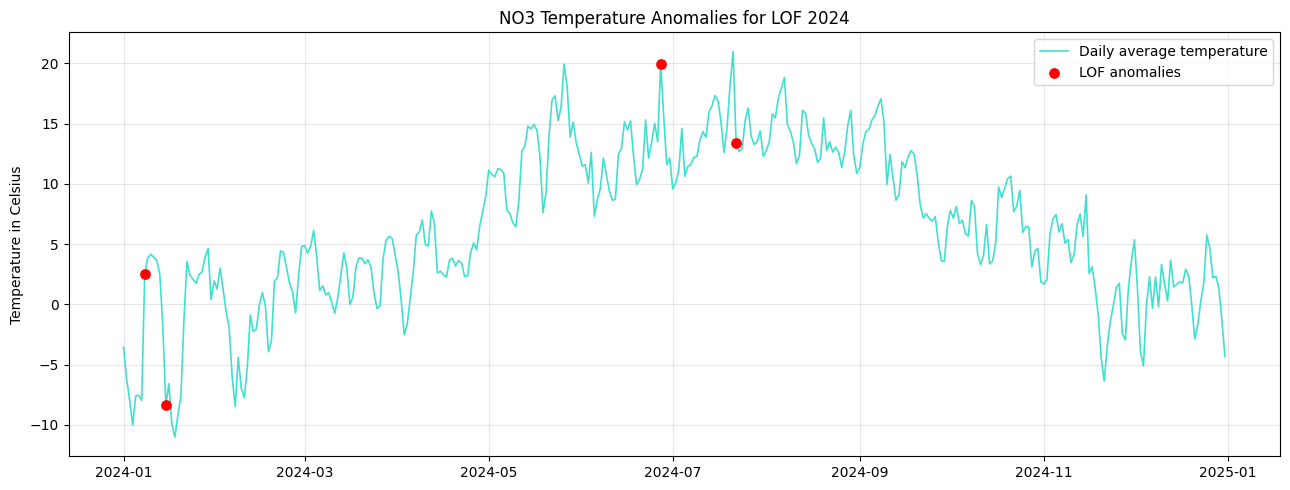

Total observations: 366
Temerature anomalies: 4
Outlier percentage 1.092896174863388


,temperature_c,lof_score
time,,
2024-01-08 00:00:00+00:00,2.508333,3.451653
2024-01-15 00:00:00+00:00,-8.358333,2.123594
2024-06-27 00:00:00+00:00,19.979167,2.407420
2024-07-22 00:00:00+00:00,13.395833,2.351866


In [ ]:
#Now to test out the new anomaly function

fig_temp, temp_summary = plot_temperature_lof(
    weather_daily,
    contamination=0.01
)

plt.show()

print("Total observations:", temp_summary["total_observations"])
print("Temerature anomalies:", temp_summary["outlier_count"])
print("Outlier percentage", temp_summary["outlier_percentage"])

display(temp_summary["outliers"])

In [ ]:


# Now we use the Magasinstatistikk data from the first reservoirs-csv file from earlier

reservoirs = pd.read_csv("reservoirs.csv")


#Here we sort out the regions 

no3_reservoirs = reservoirs[
    (reservoirs["omrType"] == "EL") &
    (reservoirs["omrnr"] == 3)
].copy()


no3_reservoirs["dato_Id"] = pd.to_datetime(
    no3_reservoirs["dato_Id"]
)

no3_reservoirs["fyllingsgrad"] = pd.to_numeric(
    no3_reservoirs["fyllingsgrad"],
    errors="coerce"
)

reservoir_series = (
    no3_reservoirs
    .dropna(subset=["dato_Id", "fyllingsgrad"])
    .groupby("dato_Id")["fyllingsgrad"]
    .mean()
    .sort_index()
    .resample("W-SUN")
    .mean()
)

print("Weekly observations:", len(reservoir_series))
print("Missing weeks:", reservoir_series.isna().sum())
print("First date:", reservoir_series.index.min())
print("Last date:", reservoir_series.index.max())


Weekly observations: 1653
Missing weeks: 0
First date: 1995-01-08 00:00:00
Last date: 2026-09-06 00:00:00


In [ ]:
#With the data sorted out we can define the STL decomposition 

def plot_reservoir_stl(
    series,
    seasonal_smoother=13,
    trend_smoother=105,
    robust=True
):

    if seasonal_smoother < 3 or seasonal_smoother % 2 == 0:
        raise ValueError(
            "Seasonal Smoother must be an odd integer >= 3."
        )

    if trend_smoother <= 52 or trend_smoother % 2 == 0:
        raise ValueError(
            "trend_smoother must be an odd number and greater than 52."
        )
    if len(series) < 104:
        raise ValueError("At least 104 weekly observations required.")

    model = STL(
        series,
        period=52,
        seasonal=seasonal_smoother,
        trend=trend_smoother,
        robust=robust
    )

    result = model.fit()

    fig, axes = plt.subplots(
        4, 1,
        figsize=(13,10),
        sharex=True
    )

    axes[0].plot(series.index, series.values)
    axes[0].set_title("Observeed Reservoir Filling for NO3")
    axes[0].set_ylabel("Filling degree")

    axes[1].plot(result.trend.index, result.trend.values)
    axes[1].set_title("Trend")

    axes[2].plot(result.seasonal.index, result.seasonal.values)
    axes[2].set_title("Residual Component")
    
    axes[3].plot(result.resid.index, result.resid.values)
    axes[3].set_title("Residual Component")
    axes[3].set_xlabel("Date")

    for ax in axes:
        ax.grid(alpha=0.4)


    fig.tight_layout()

    return fig 
    

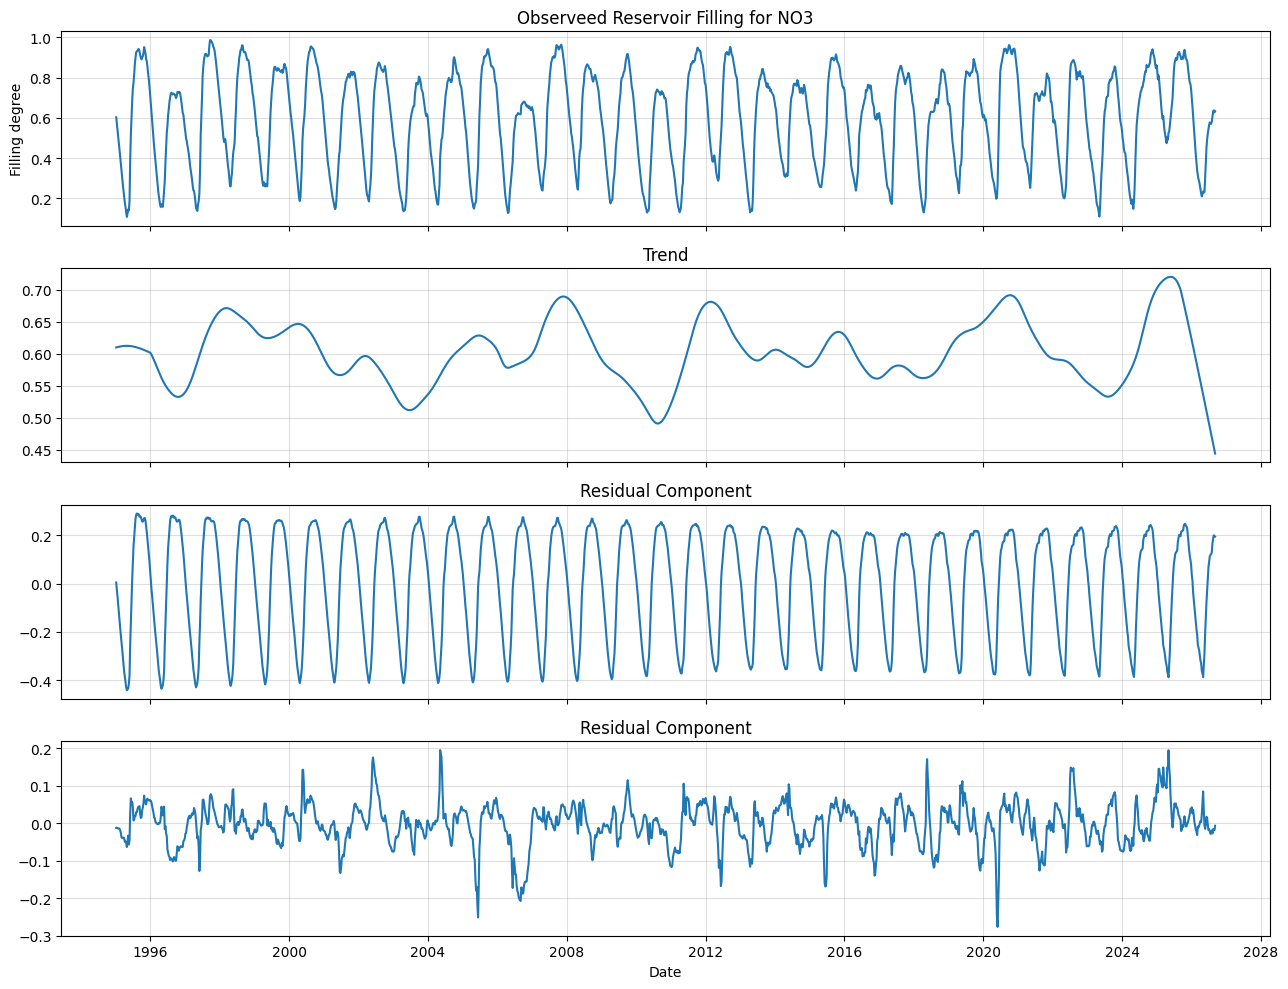

In [ ]:
#Now we test the decomposition with default parameters from our function

fig_stl = plot_reservoir_stl(
    reservoir_series,
    seasonal_smoother=13,
    trend_smoother=105,
    robust=True
)

plt.show()



In [ ]:
#For the spectofram we use the STL decomposition analysis to show the change over time

def plot_reservoir_spectrogram(
    series, 
    window_length=104,
    window_overlap=52
):

    series= series.sort_index()


    if series.isna().any():
       raise ValueError("The time series contains missing values. Please try again")

    if not isinstance(series.index, pd.DatetimeIndex):
        raise ValueError("The index must have dates.")

    if len(series) < window_length:
        raise ValueError(
            "Window length cannot exceed the number of observations."
        )

    if window_length < 4:
        raise ValueError("Window length must be 4 weeks or more.")

    if not 0 <= window_overlap < window_length:
        raise ValueError(
            "Overlap must be between 0 and length - 1"
        )

    if not (series.index.to_series().diff().dropna()
            == pd.Timedelta(days=7)).all():
        raise ValueError("Data must be sampled weekly, on a regular basis")

    frequencies, times, power = spectrogram(
        series.to_numpy(dtype=float),
        fs=1.0,
        window="hann",
        nperseg=window_length,
        noverlap=window_overlap,
        detrend="linear",
        scaling="spectrum"
    )

    frequencies_year = frequencies * 52.18

    dates = series.index[0] + pd.to_timedelta(
        times * 7,
        unit="D"
    )

    date_numbers = mdates.date2num(dates.to_pydatetime())

    

    #We use the log scale, as this will highlight of the weaker patterns in the data
    power_db = 10 * np.log10(
        np.maximum(power, 1e-12)
    )

    fig, ax = plt.subplots(figsize=(13,6))

    mesh = ax.pcolormesh(
        date_numbers,
        frequencies_year,
        power_db,
        shading="auto",
        cmap="Blues"
    )

    fig.colorbar(
        mesh,
        ax=ax,
        label="Spectral power (dB)"
    )

    ax.axhline(
        y=1,
        color="indigo",
        linestyle="--",
        linewidth=1.4,
        label="Annual cycle"
    )

    ax.set_ylim(0,8)
    ax.xaxis_date()
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y")
    )

    ax.set_title("NO3 Reservoir Filling - Spectrogram")
    ax.set_xlabel("Date")
    ax.set_ylabel("Frequency (cycles/year)")
    ax.legend(loc="upper right")

    fig.autofmt_xdate()
    fig.tight_layout()

    return fig
    


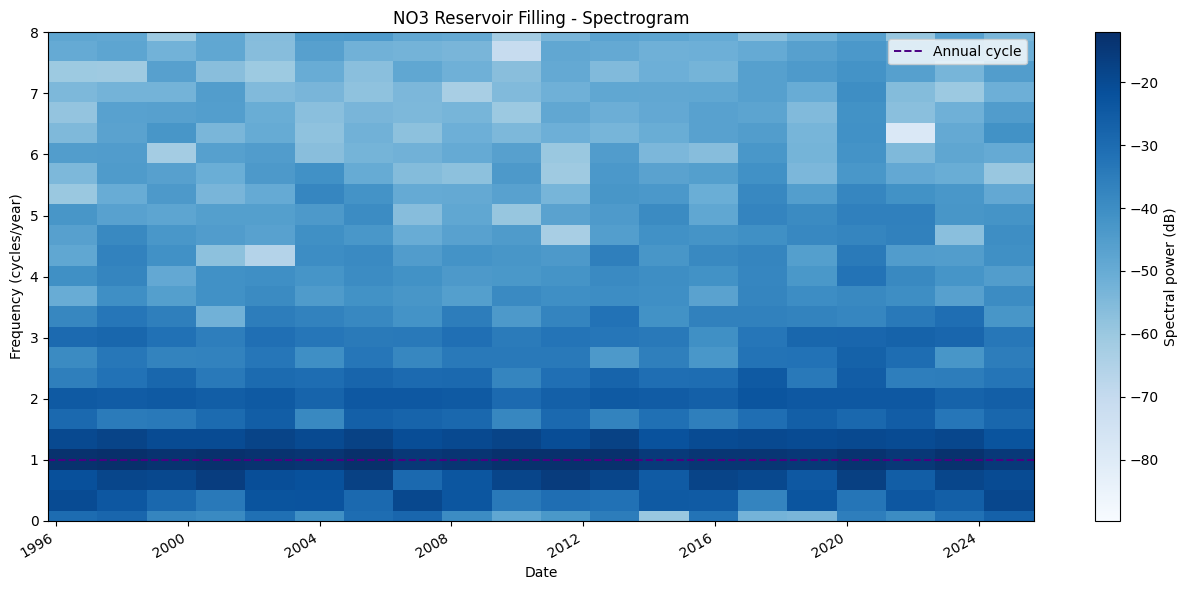

Spectrogram generated!
Weekly observations: 1653
Window length 156 weeks
Window overlap: 78 weeks


In [ ]:
#Now we just apply the function in use with some example values and see how it turns out. 

fig_spectrogram = plot_reservoir_spectrogram(
    reservoir_series,
    window_length=156,
    window_overlap=78
)

plt.show()

print("Spectrogram generated!")
print("Weekly observations:", len(reservoir_series))
print("Window length", 156, "weeks")
print("Window overlap:", 78, "weeks")